# Exercitiul 1

In [6]:
from random import sample
def prob_cond(nr_sim):
    countA, countB = 0, 0
    for _ in range(nr_sim):
        bile_extrase = sample(['red','blue','green'], counts=[5,3,2], k=3)
        if 'red' in bile_extrase:
            countA+=1 # A : "cel putin o bila rosie extrasa"
            if len(set(bile_extrase))==1: # B : "toate bilele extrase sunt de aceeasi culoare" -> P(A si B)
                countB+=1
    return countB/countA # Probabilitate conditionata P(B|A)
prob_cond(500000)

0.09039544325115566

In [ ]:
from math import comb

# Calcul probabilitate conditionata P(B|A)
prob_a_and_b = comb(5,3)/comb(10,3) # P(A si B)
prob_a = 1 - comb(5,3)/comb(10,3) # P(A)
prob_b_given_a = prob_a_and_b/prob_a
print(prob_b_given_a)


0.09090909090909091


# Exercitiul 2
Se simuleaz  aruncarea unui zar de 500 de ori. Afisati histograma frecventelor relative ale numerelor obtinute si barele corespunz toare probabilit tilor teoretice, înlocuind semnele de întrebare din codul urmator:

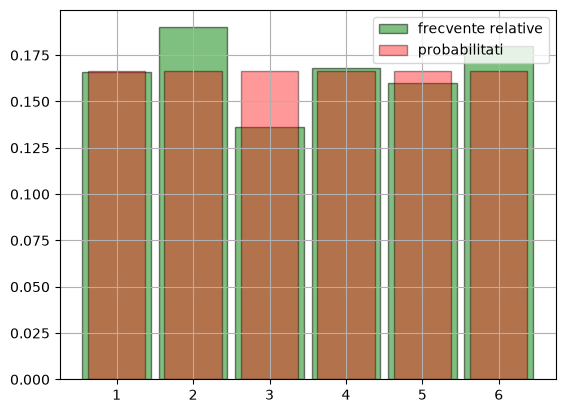

In [22]:
from random import randrange
from matplotlib.pyplot import bar, hist, grid, show, legend
data = [randrange(1,7) for _ in range(500)]
# print(data)
bin_edges = [k+0.5 for k in range(7)]
hist(data, bin_edges, density = True, rwidth = 0.9, color = 'green', edgecolor = 'black',
alpha = 0.5, label = 'frecvente relative')
distribution = dict([(i, 1/6) for i in range(1,7)])
bar(distribution.keys(), distribution.values(), width = 0.75, color = 'red', edgecolor = 'black', alpha = 0.4, label = 'probabilitati')
legend(loc = 'upper right')
grid()
show()

# Exercitiul 3
Într-o urna sunt 6 bile cu cifra 1 inscriptionata  si 4 bile cu cifra 0. Se extrag aleator cu returnare 5 bile din urna. Fie X variabila aleatoare care indica suma numerelor de pe bilele extrase.

### a) Generati o list de 1000 de valori pentru X.
### b) Afisati histograma frecventelor relative si barele corespunzatoare valorilor teoretice.


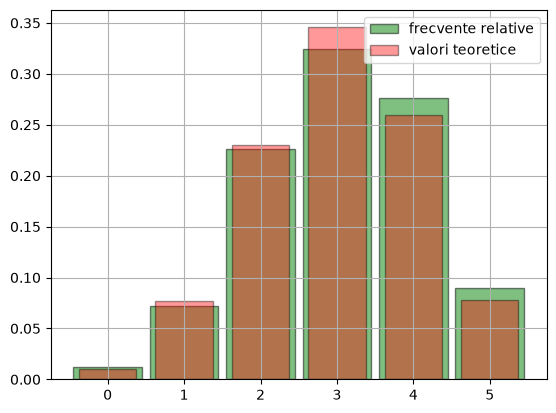

In [ ]:
# succes = 1
# p = P(succes) = 6/10
# n = 5
# X ~ Bino(n, p) = Bino(5, 6/10)

from scipy.stats import binom
from matplotlib.pyplot import bar, hist, grid, show, legend

data = binom.rvs(n=5, p=6/10, size=1000)
bin_edges = [k+0.5 for k in range(-1,6)]
hist(data, bin_edges, density = True, rwidth = 0.9, color = 'green', edgecolor = 'black',alpha = 0.5, label = 'frecvente relative')

# P(X = i) teoretic
distrib = dict([(i, binom.pmf(i, n=5, p=6/10)) for i in range(0, 6)])
bar(distrib.keys(), distrib.values(), width = 0.75, color = 'red', edgecolor = 'black', alpha = 0.4, label = 'valori teoretice')
legend(loc = 'upper right')
grid()
show()


### c) Estimati probabilitatea P (1<X<=4) si afisati valoarea teoretica 

In [25]:
# P(x<=i) = binom.cdf(i, n=5, p=6/10)
# P(1 < X <= 4) = P(X <= 4) - P(X <= 1)

from numpy import mean

P = binom.cdf(4, n=5, p=6/10) - binom.cdf(1, n=5, p=6/10)
print(P)

data = binom.rvs(n=5, p=6/10, size=1000)
print(mean([(1 < x <= 4) for x in data]))


0.8351999999999999
0.845


# Exercitul 4
### a) Implementati în Python urmtorul algoritm Monte Carlo:
Input: Un vector v cu 100 de elemente.
1. Se alege aleator un numar k din multtimea {1, 2, . . . , 100}.
2. Se aleg aleator, fara returnare, k elemente din v, pentru a forma o sublista w a lui v.
Output: maximul lui w.

### b) Estimati probabilitatea ca outputul algoritmului sa fie 100 pentru v=[1,2,...,100]

In [57]:
from random import randint, sample

def monte_carlo_max(v, k):
    w = sample(v, k=k)
    return max(w)

v = [i for i in range(101)]
k = randint(1, 100)

count_100 = 0
total = 50000
for _ in range(total):
    max_w = monte_carlo_max(v, k)
    if max_w == 100:
        count_100 += 1

print(f"Probability of selecting 100 as the maximum: {count_100 / total}")



Probability of selecting 100 as the maximum: 0.56288


In [ ]:
# P(max w == 100) = Sum_{j=1}^{100} P(max w == 100 | k = j) * P(k = j)
# P(k = j) = 1/100 for j in 1..100
# P(max w == 100 | k = j) = j/100 for j in 1..100
rez = sum((j/100) * (1/100) for j in range(1,101))
print(rez)

0.505
